# iPhone LiDAR room mapping with YOLOE-26
This notebook uses the calibrated research geometry and the upgraded scene-conditioned segmentation detector. Original notebooks remain baseline artifacts. The visual reference frames are disjoint from the qualitative audit frames; this is same-scene adaptation, not a zero-shot benchmark.

Scale is inferred from exported depth and ARKit poses. Solid walls are observed segments; dashed room closure is inferred. Object surfaces remain partial. See `research/ROOM_UPGRADE_REPORT.md` for validation and limits.

In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd()
if not (ROOT / 'research').exists():
    raise RuntimeError('Start this notebook in D:/VLM-maps')
sys.path.insert(0, str(ROOT / '.packages'))
sys.path.insert(0, str(ROOT / 'research'))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['MPLCONFIGDIR'] = str(ROOT / '.matplotlib')
import room_upgrade, room_views
from IPython.display import display, Image, HTML
print('Runtime:', sys.executable)
print('Chosen detector: YOLOE-26l with room visual exemplars')

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Runtime: C:\Users\yuvar\anaconda3\python.exe
Chosen detector: YOLOE-26l with room visual exemplars


In [2]:
# Uses existing inference caches. To recompute, preserve and move the relevant
# outputs/room_refined cache files before running; model weights are local.
room_views.main()
manifest = json.loads((room_upgrade.OUT / 'room_view_manifest.json').read_text())
mesh = json.loads((room_upgrade.OUT / 'mesh_metrics.json').read_text())
display(manifest, mesh)

Using cached mask observations


Supported objects: [('air vent', 132), ('armchair', 1688), ('beanbag', 1376), ('door', 4456), ('picture', 127), ('sofa', 3937), ('storage table', 1712), ('window', 1984), ('window', 1163)]


ROOM VIEWS COMPLETE


{'objects': 9,
 'classes': ['air vent',
  'armchair',
  'beanbag',
  'door',
  'picture',
  'sofa',
  'storage table',
  'window',
  'window'],
 'selected_frames': 107,
 'total_runtime_seconds': 11.526729800000112,
 'detector': 'YOLOE-26l instance segmentation with disjoint visual reference frames',
 'localization': 'Depth-mask pixels, two-view voxel support, CLIP semantic review, registered-cloud support',
 'limitations': 'Offline reconstruction; inferred calibration/scale; partial object surfaces; no annotated detection/shape benchmark. Structural envelope is inferred.'}

{'vertices': 128254,
 'triangles': 247387,
 'cutaway_triangles': 128152,
 'tsdf_voxel_pose_units': 0.025,
 'tsdf_truncation_pose_units': 0.1,
 'dense_pixel_support_gate': 0.11,
 'object_surface_points': 16575,
 'render': 'Actual fused vertex RGB; interactive full-room/cutaway/object layers. No generative replacement or synthetic geometry completion.'}

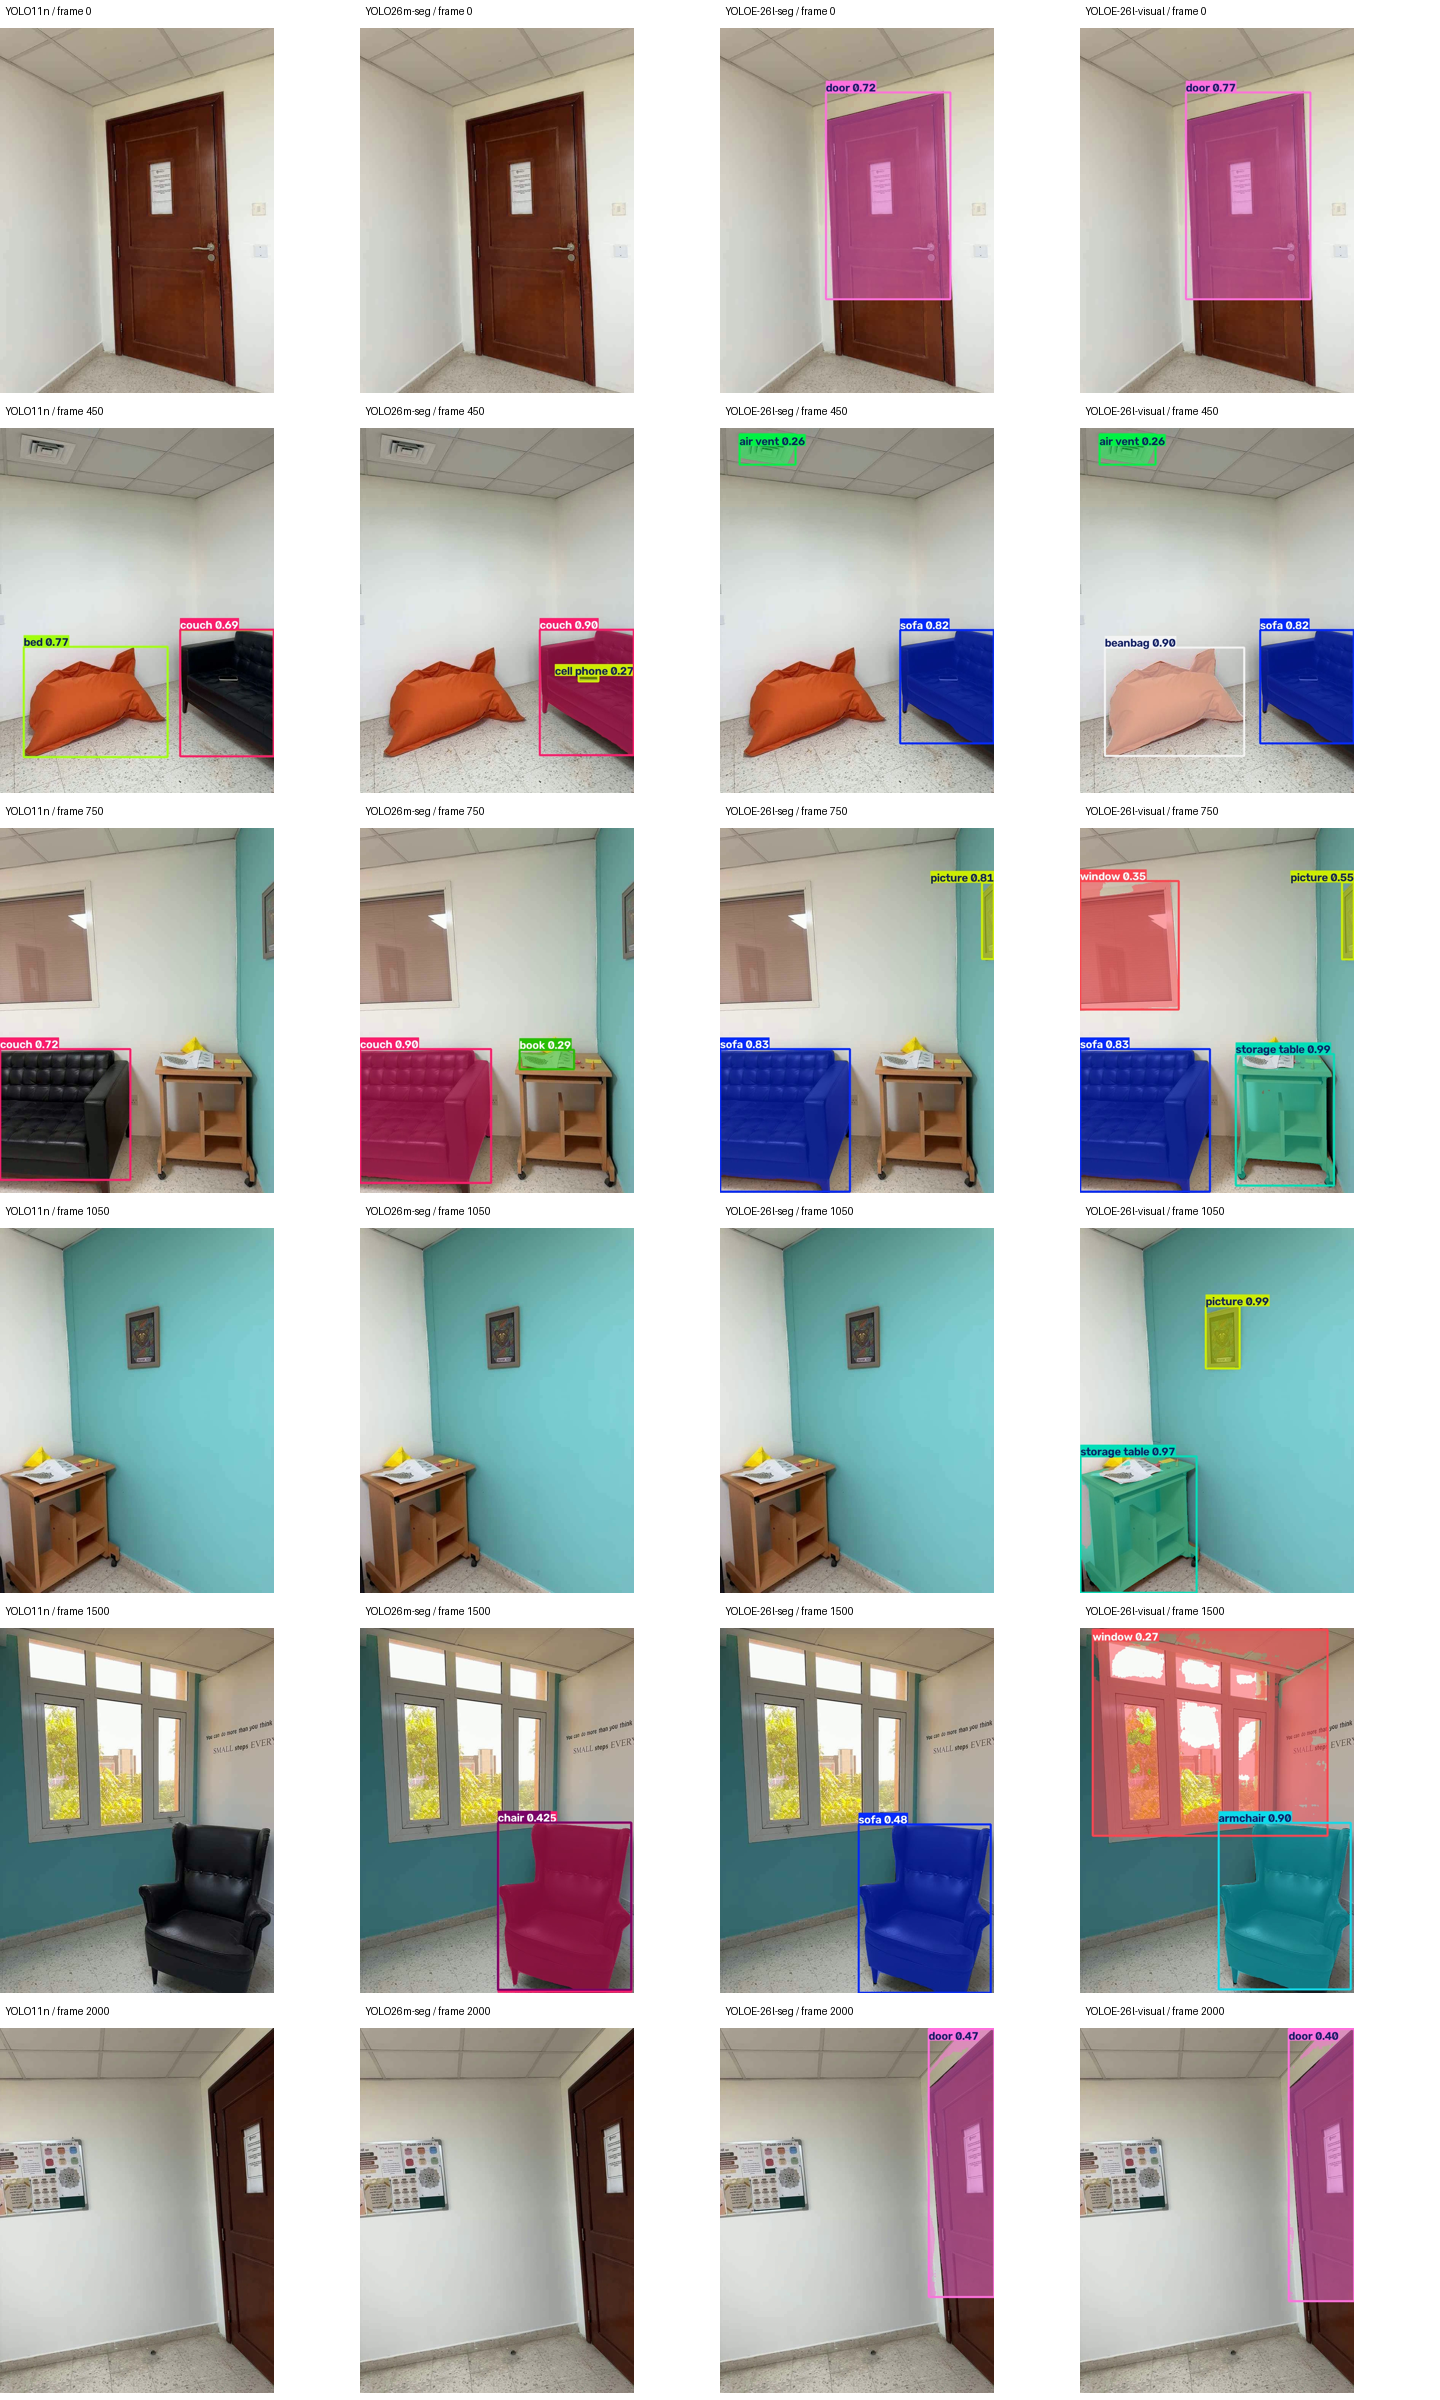

Matched frames and thresholds; detections are qualitative evidence, not mAP.


In [3]:
display(Image(filename=str(room_upgrade.OUT / 'detector_comparison_contact.png')))
print('Matched frames and thresholds; detections are qualitative evidence, not mAP.')

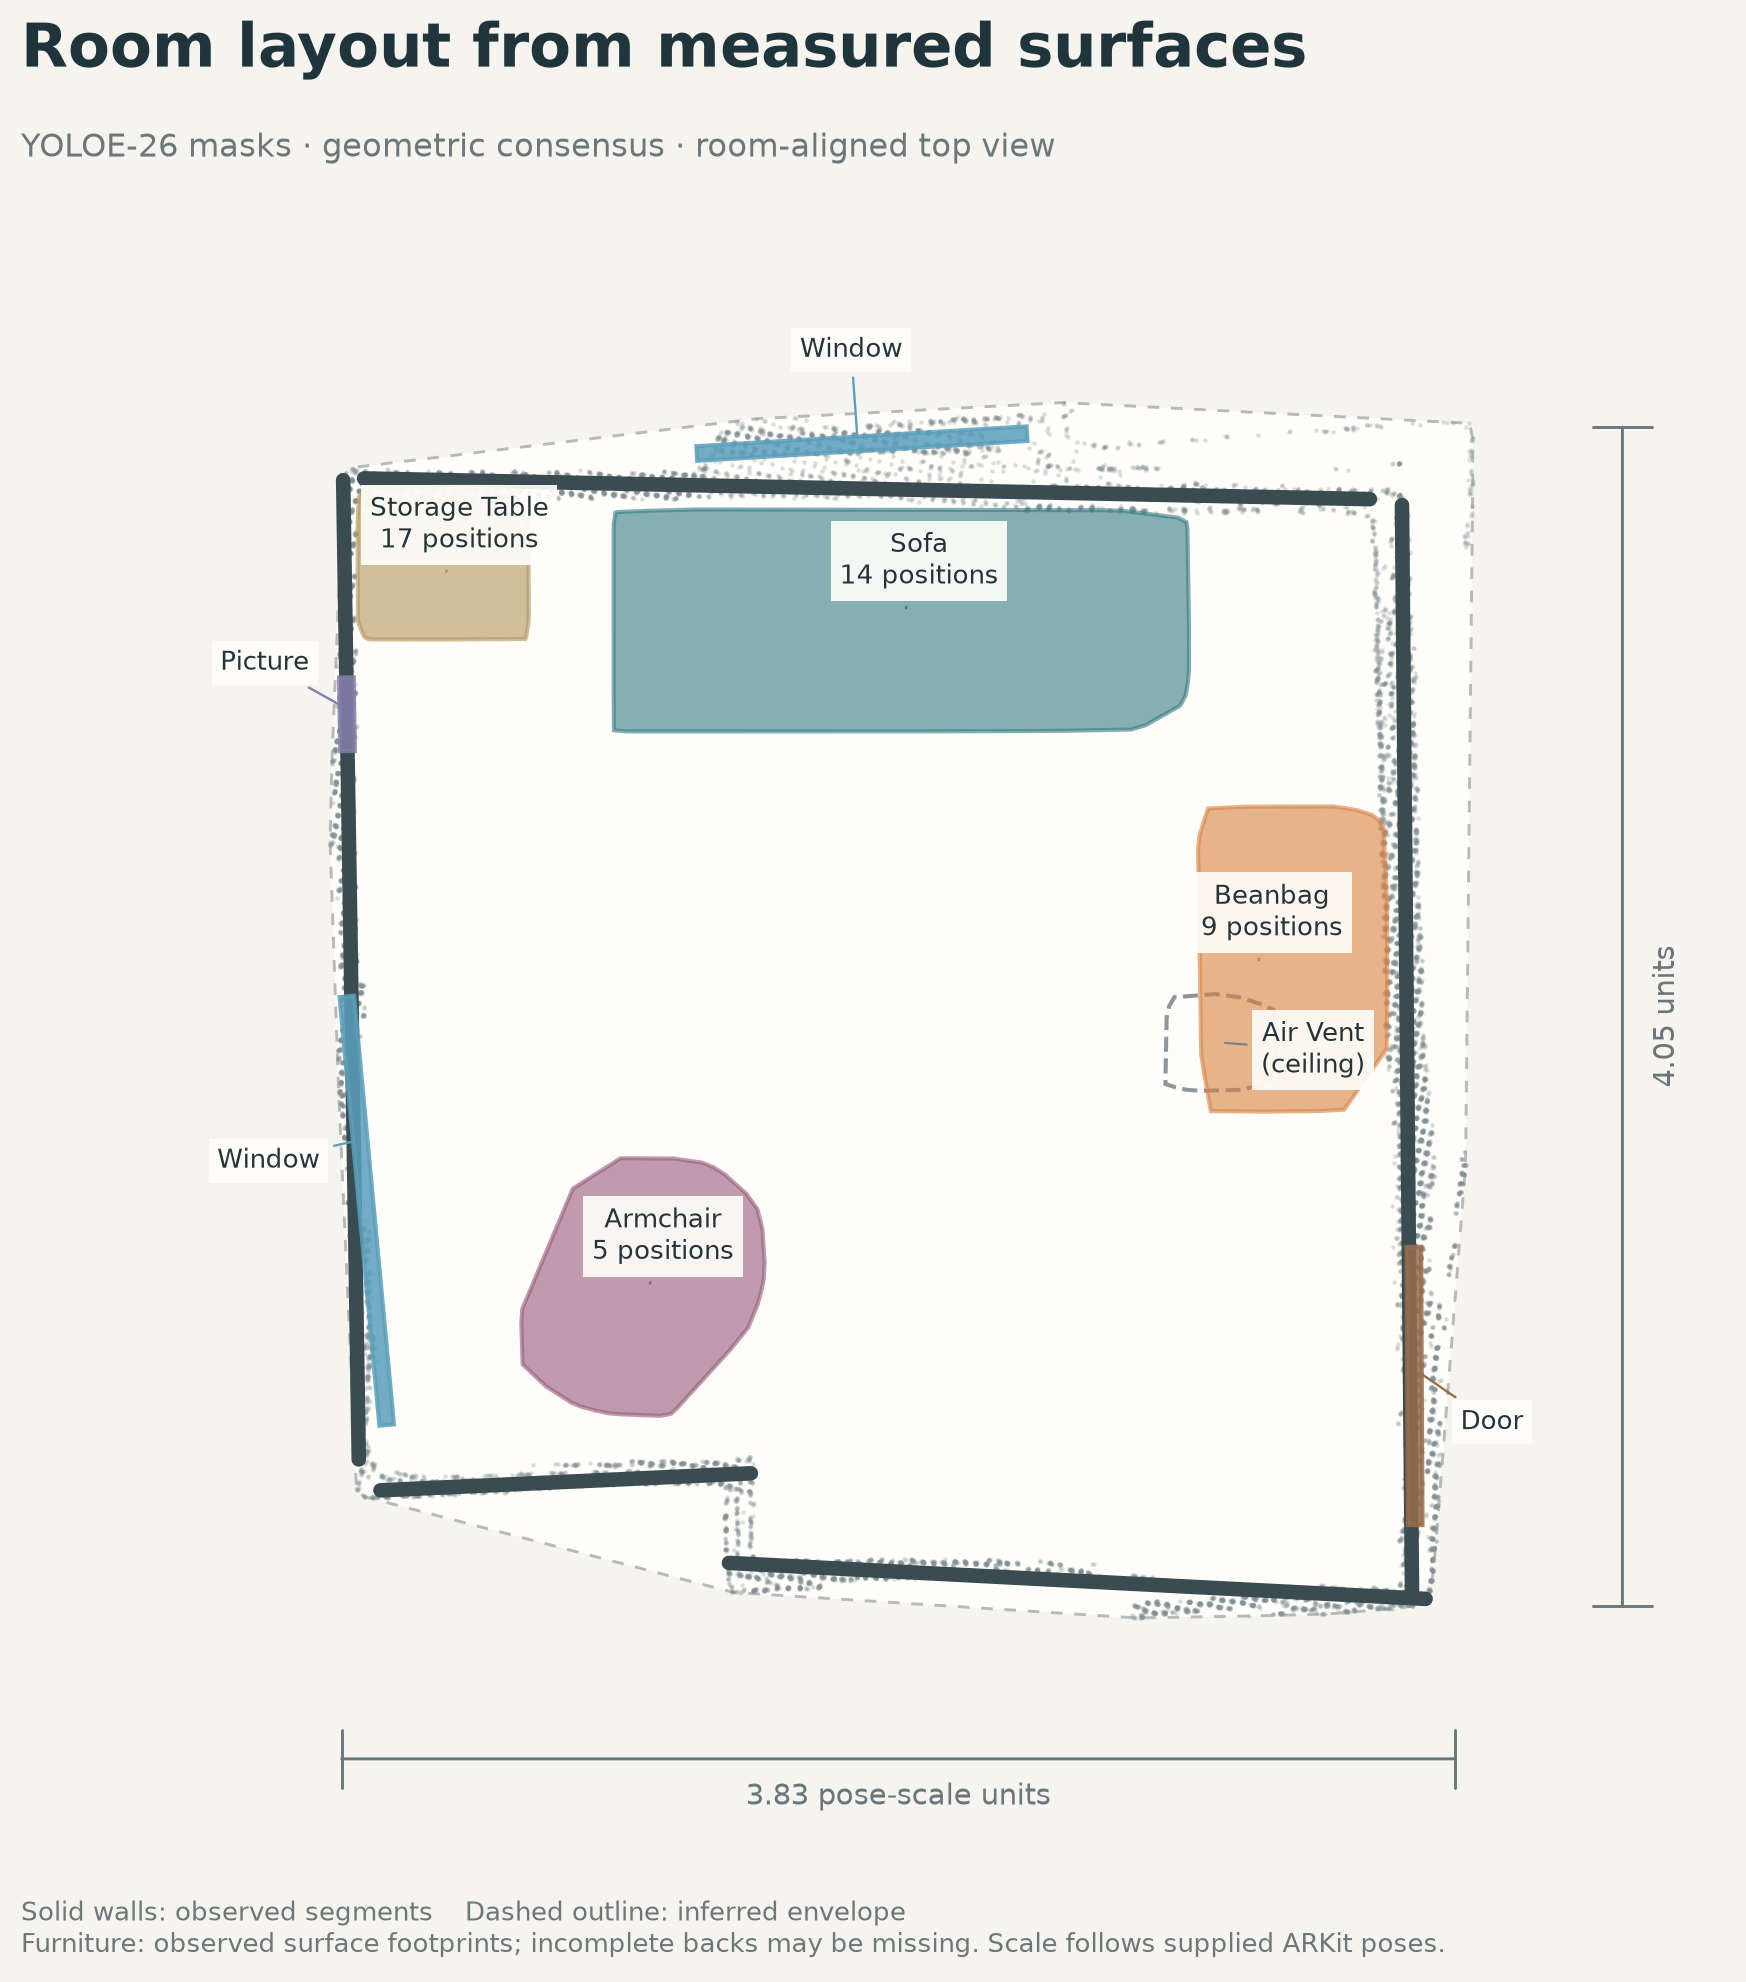

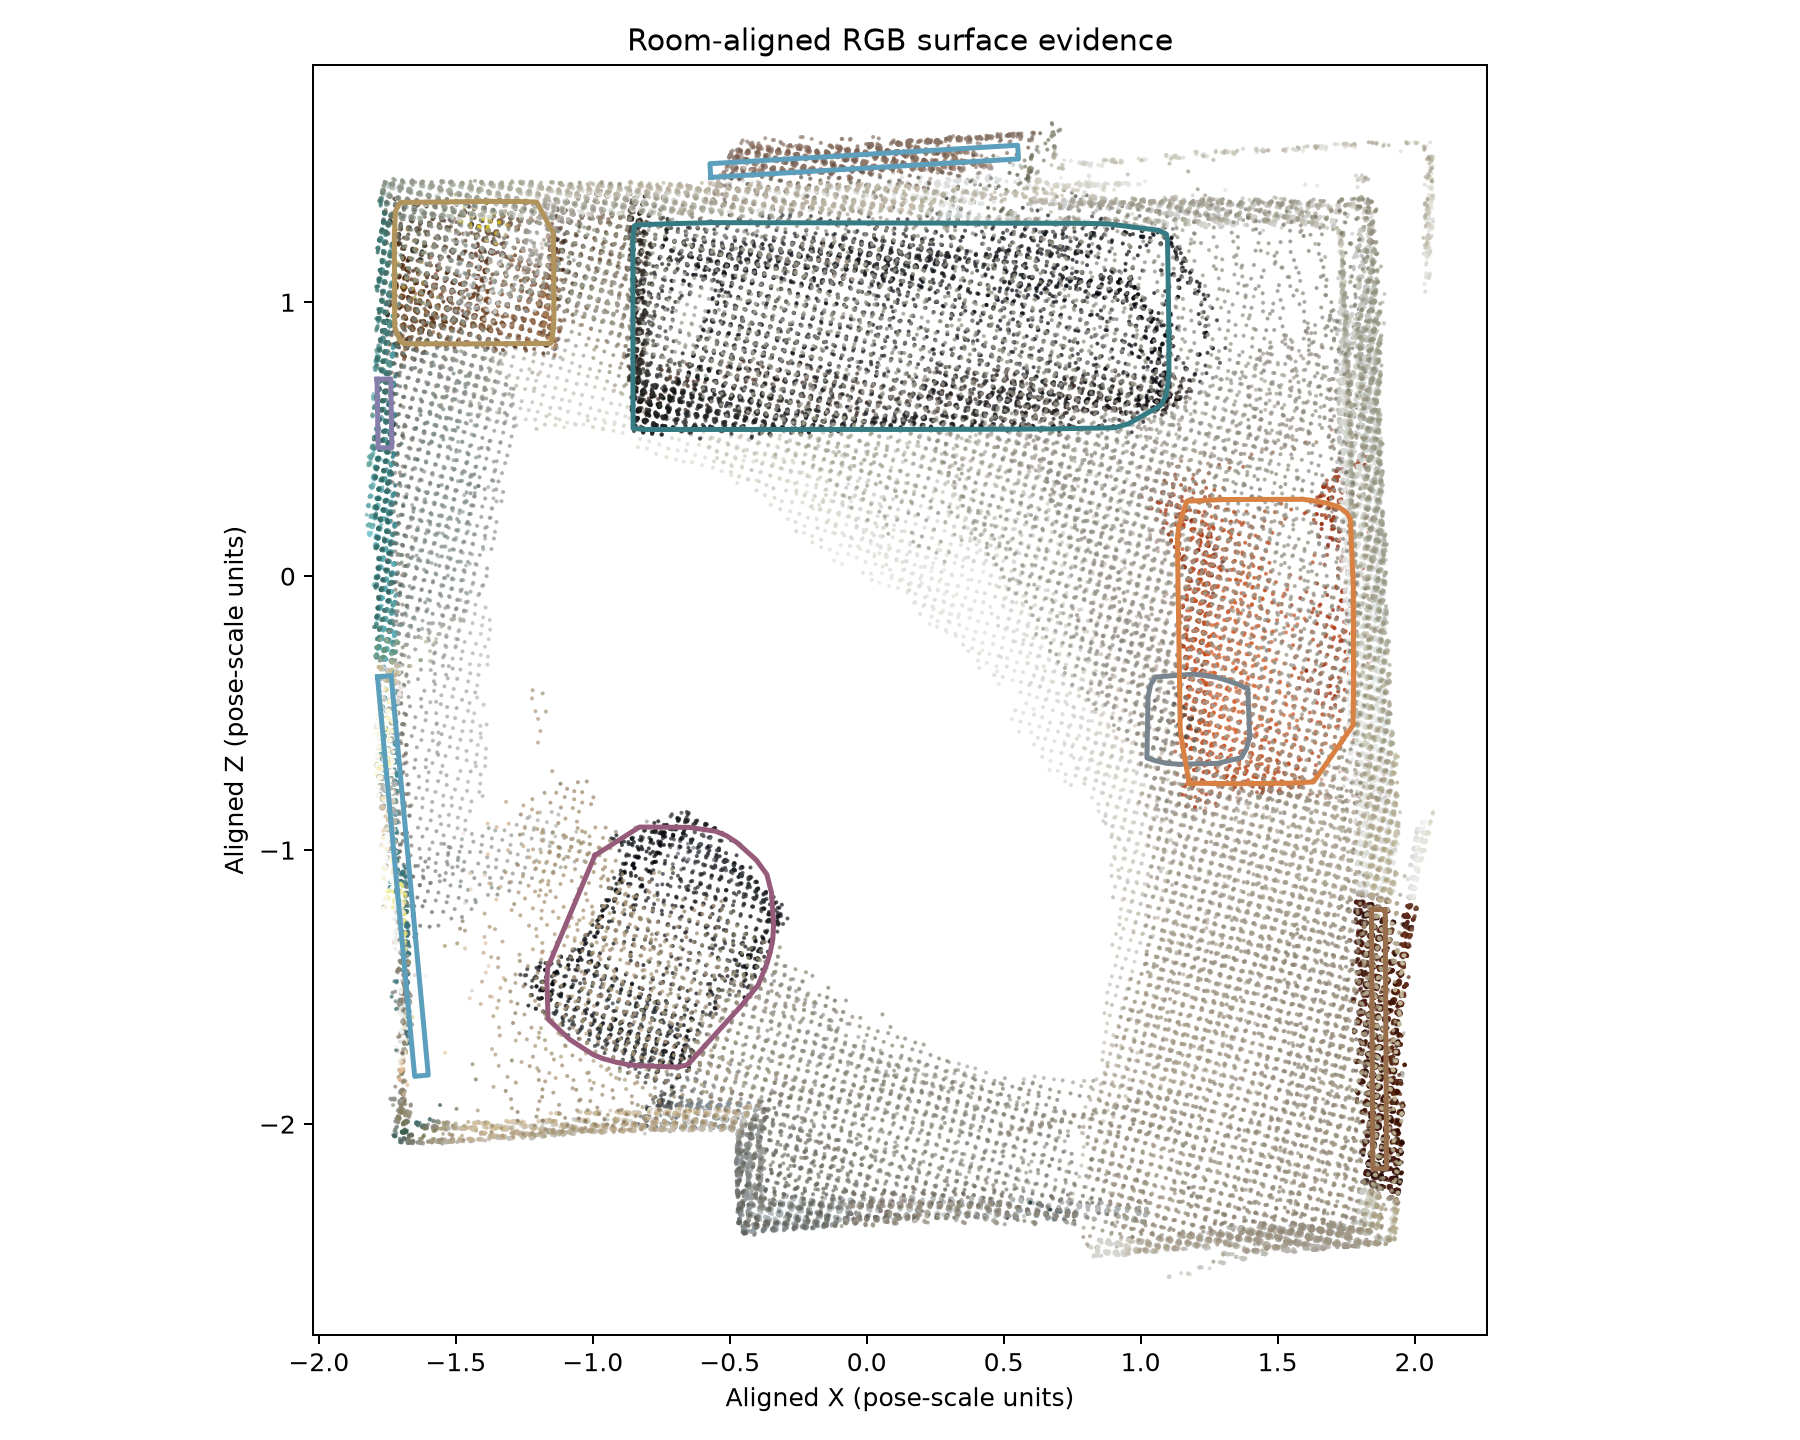

In [4]:
display(Image(filename=str(room_upgrade.OUT / 'room_floorplan.png')))
display(Image(filename=str(room_upgrade.OUT / 'room_topview_rgb.png')))

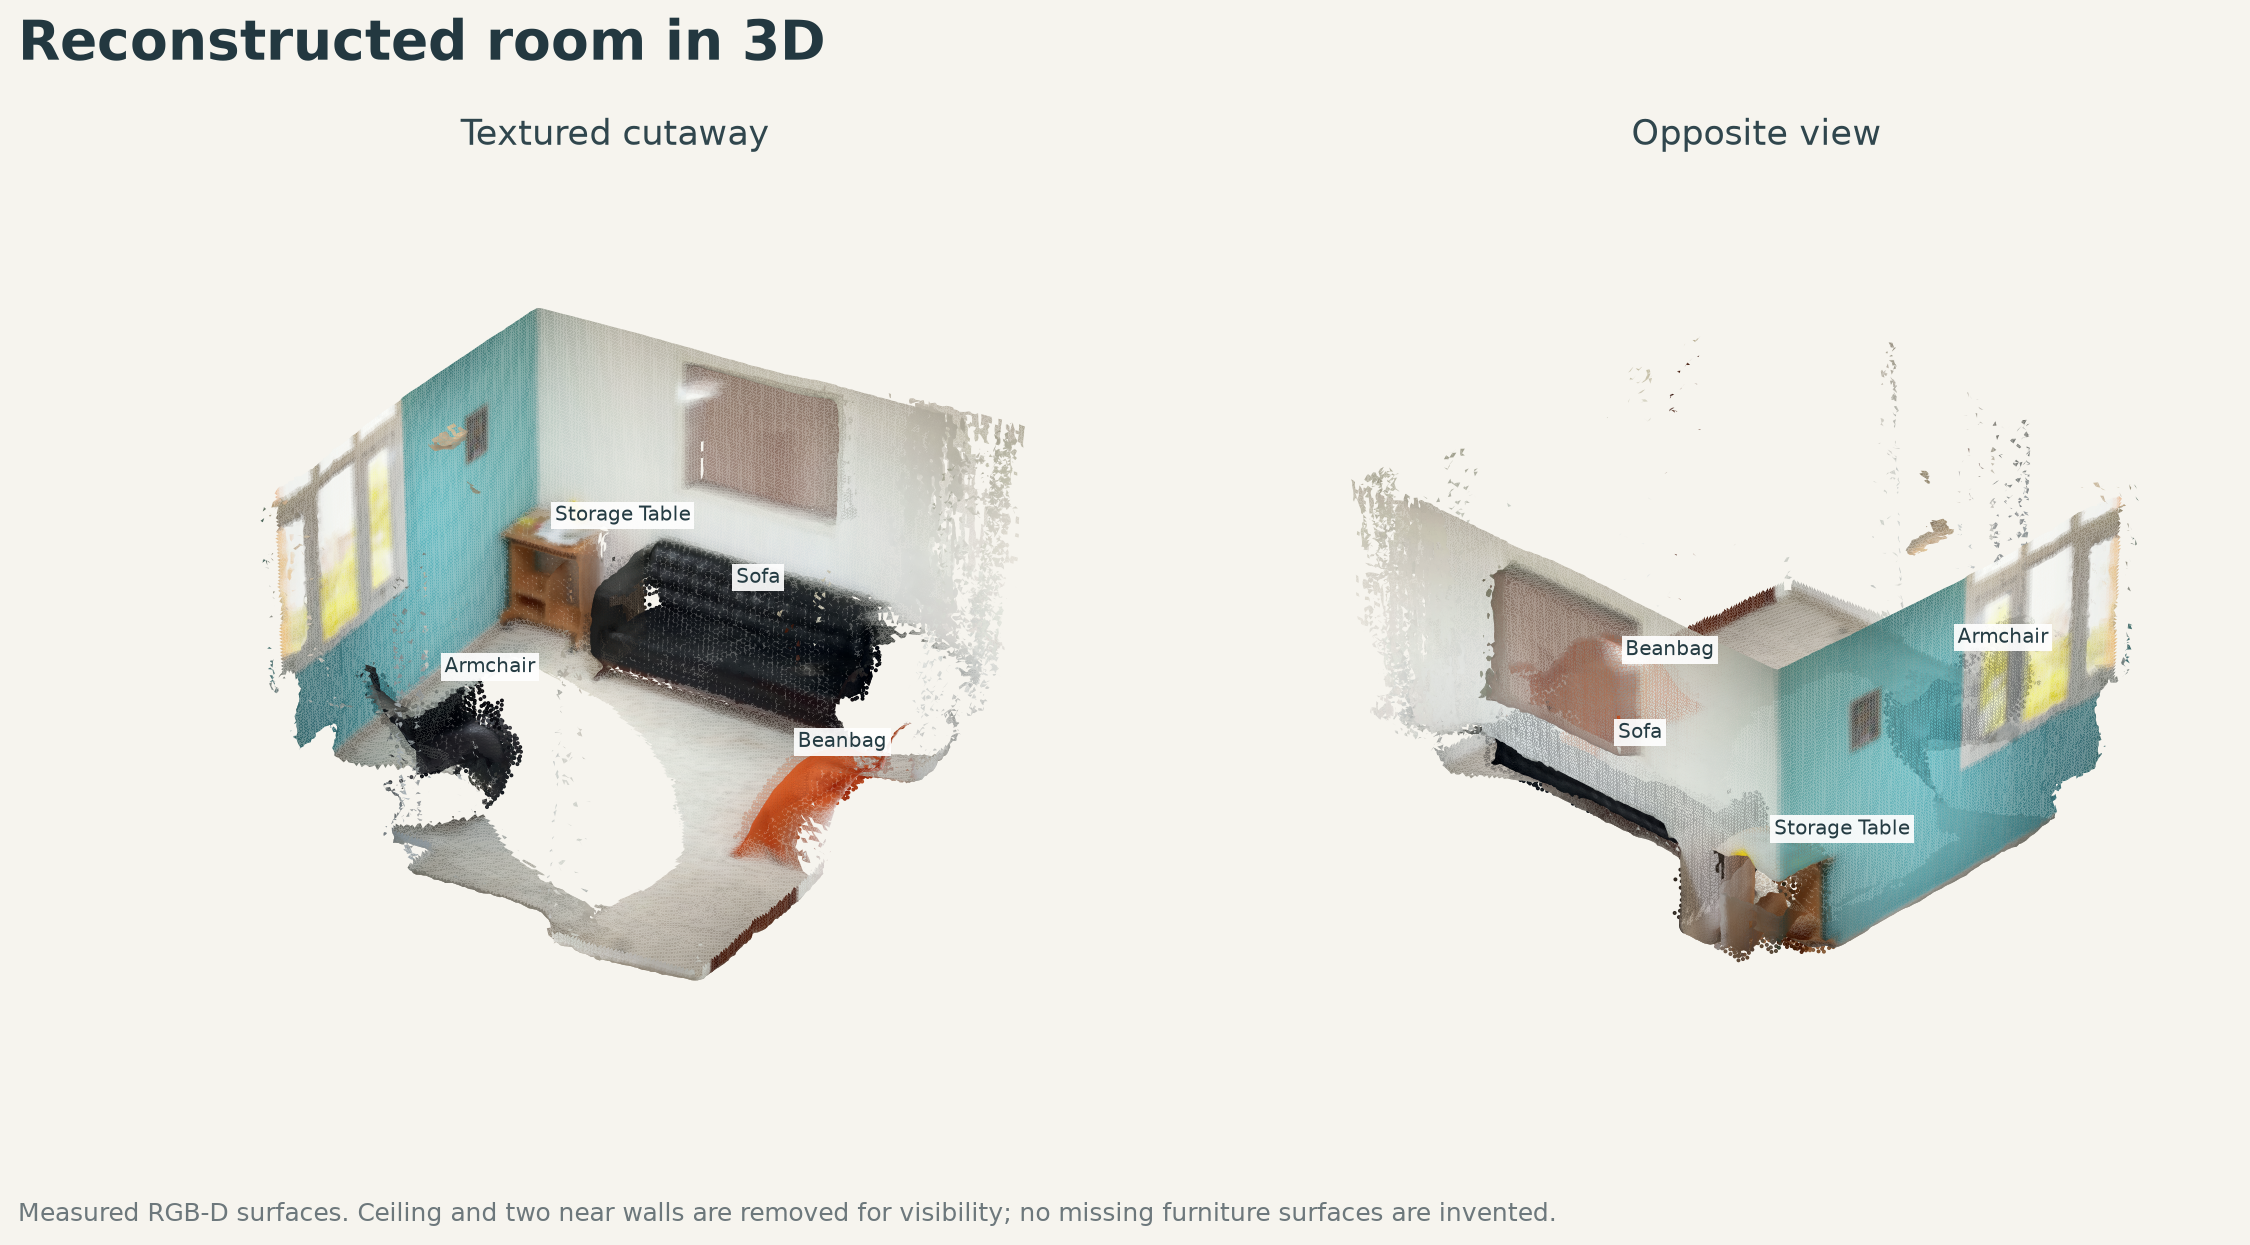

In [5]:
display(Image(filename=str(room_upgrade.OUT / 'room_3d_cutaway.png')))
display(HTML('<a href="outputs/room_refined/room_3d_interactive.html" target="_blank">Open standalone interactive 3D: cutaway / full room / objects</a>'))